# 02 · A first surrogate, one footprint

**Milestone 2.** One footprint (ref33x31), 1,024 training soils, 32 hold-out soils that no
model sees until it is evaluated. The goal is a first honest number, and an understanding of
where the error comes from.

This notebook works on the full band, 0.45–33.2 Hz. Its finding that the error lives above
~15 Hz led to the modelling band 0.45–15 Hz used from Milestone 3 on.

1. **Data and the error metric.**
2. **Baselines:** predict the average curve; then k-nearest neighbours, with k chosen by
   cross-validation.
3. **PCA:** how many shapes are needed to describe the curves, and the error floor that sets.
4. **Gaussian processes** on the PCA coefficients, with uncertainty.
5. **Where the error comes from,** by frequency band.
6. **Learning curves:** would more data help?
7. **What the GP learned** about the inputs.
8. **The experiment table,** and findings.

The GP fits use all CPU cores (`n_jobs=-1`); the whole notebook takes about 15 minutes on a desktop CPU.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyRegressor
from sklearn.metrics import make_scorer
from sklearn.model_selection import GridSearchCV, KFold

from surrogate import style
from surrogate.data import load_dataset, make_targets, targets_to_K
from surrogate.experiments import log_experiment, read_experiments
from surrogate.metrics import error_spectrum, summarize, target_errors
from surrogate.models import PCAGP, TermScaler, input_features, knn_model

style.apply()
ds = load_dataset(fmax=None)                          # 0.45-33.2 Hz (this notebook keeps the full band)
f = ds.freqs
train = ds.select(mesh="ref33x31", split="train")     # 1,024 Halton soils, in Halton order
test = ds.select(mesh="ref33x31", split="test")       # 32 random soils: kept for evaluation only

X_train, x_names = input_features(train)
X_test, _ = input_features(test)
Y_train, spec = make_targets(train.K)
Y_test, _ = make_targets(test.K)
terms = list(spec.terms)
print(f"X_train {X_train.shape}  Y_train {Y_train.shape}  |  X_test {X_test.shape}  Y_test {Y_test.shape}")
print("inputs:", x_names)
print(*ds.notes, sep="\n")

X_train (1024, 8)  Y_train (1024, 2112)  |  X_test (32, 8)  Y_test (32, 2112)
inputs: ['t_L1', 't_L2', 't_L3', 't_L4', 't_L5', 't_L6', 't_L7', 'log_g']
loaded dataset_v1.npz
ref33x31: K moved from NRADIER to the centroid (r = 1.171, 0.807 m)
frequencies below 0.45 Hz dropped (1)


## 1 · The error metric

For one case and one term, the error is the largest deviation anywhere in the band, divided by
the largest |K| of the true curve, in percent:

$$e = 100 \cdot \frac{\max_f |\hat K(f) - K(f)|}{\max_f |K(f)|}$$

It is strict (one bad frequency sets the error) and engineering-friendly (a percentage of the
curve's own size). Over the 32 test cases it is summarised three ways (`surrogate/metrics.py`):

- **err_<term>:** the 95th percentile over the test cases, "95 % of new soils are within this";
- **err_worst:** the largest of those, the bottleneck term;
- **err_mean:** the mean over cases and terms, the most stable number for comparing models.

Every model below is evaluated with the same function, `evaluate`, so the comparison is fair.

In [2]:
results = {}          # name -> summary, filled as we go

def evaluate(name, Y_pred, band=None):
    e = target_errors(Y_test, Y_pred, spec, freqs=f, band=band)
    s = summarize(e, terms)
    results[name] = s
    return e, s

def show(names=None):
    names = names or list(results)
    return pd.DataFrame({n: results[n] for n in names}).T.round(2)

## 2 · Baselines

**The mean curve.** The simplest possible "model" predicts the average training curve for
every soil. Any real model must beat it; how far it beats it says how much of the variation it
explains. scikit-learn ships this as `DummyRegressor`.

**k-nearest neighbours.** Predict a weighted average of the k training soils whose inputs are
closest (inputs standardised first, so that metres and log(g) count alike). k is a
**hyperparameter**: chosen by us, not learned. It is chosen by **5-fold cross-validation** on
the training set only: split the 1,024 soils into 5 parts, fit on 4, score on the fifth,
rotate, average. The 32 test soils play no part in the choice; using them would leak test
information into the model and make the final number optimistic.

In [3]:
mean_model = DummyRegressor(strategy="mean").fit(X_train, Y_train)
evaluate("mean curve", mean_model.predict(X_test))

scorer = make_scorer(lambda yt, yp: target_errors(yt, yp, spec).mean(), greater_is_better=False)
search = GridSearchCV(knn_model(spec), {"regressor__kneighborsregressor__n_neighbors": [1, 2, 3, 5, 8, 13, 21]},
                      scoring=scorer, cv=KFold(5, shuffle=True, random_state=0))
search.fit(X_train, Y_train)
cv_table = pd.DataFrame({"k": search.cv_results_["param_regressor__kneighborsregressor__n_neighbors"],
                         "CV mean error [%]": -search.cv_results_["mean_test_score"]}).set_index("k").round(2)
best_k = search.best_params_["regressor__kneighborsregressor__n_neighbors"]
print("best k:", best_k)
cv_table.T

best k: 13


k,1,2,3,5,8,13,21
CV mean error [%],25.95,22.14,21.02,19.95,19.57,19.51,19.81


In [4]:
t0 = time.perf_counter()
knn = knn_model(spec, k=best_k).fit(X_train, Y_train)
knn_fit_s = time.perf_counter() - t0
evaluate(f"kNN (k={best_k})", knn.predict(X_test))
show()

,err_Ux,err_Uy,err_Uz,err_Rx,err_Ry,err_Rz,err_Ux-Ry,err_Uy-Rx,err_worst,err_mean
mean curve,65.59,65.73,30.67,39.50,38.53,39.74,78.37,74.14,78.37,33.59
kNN (k=13),37.78,38.02,22.58,12.52,12.29,17.70,55.79,51.56,55.79,18.01


kNN halves the mean curve's error but stays poor, especially for the couplings. With eight
inputs, even the nearest of 1,024 training soils is far away: a cube of side 1/2 holds only
1/2⁸ = 1/256 of an 8-dimensional box, so a "neighbourhood" with a handful of soils in it is
wide. This is the **curse of dimensionality**, and the reason smarter interpolation is needed.

## 3 · PCA: the shapes behind the curves

Each scaled target row has 2,112 numbers, but neighbouring frequencies move together, so the
rows live close to a much smaller subspace. **PCA** finds an orthogonal basis ordered by how
much of the variation between cases each direction carries. It is the same mathematics as modal
analysis: the components are "mode shapes" of the dataset, the explained variance plays the
role of modal participation, and keeping the first few is modal truncation.

The targets are first divided per term by `TermScaler` (rocking is ~1,000 × translation, so
unscaled PCA would describe rocking only).

In [5]:
from sklearn.decomposition import PCA

scaler = TermScaler(spec).fit(Y_train)
Z_train, Z_test = scaler.transform(Y_train), scaler.transform(Y_test)
pca_full = PCA().fit(Z_train)
cum = np.cumsum(pca_full.explained_variance_ratio_)
for q in (0.99, 0.999, 0.9999):
    print(f"components for {q:.2%} of the variance: {np.searchsorted(cum, q) + 1}")

# reconstruction error on the TEST soils: the best any model predicting n coefficients can do
rec_rows = {}
for n in (5, 10, 20, 40, 60, 100):
    p = PCA(n).fit(Z_train)
    Y_rec = scaler.inverse_transform(p.inverse_transform(p.transform(Z_test)))
    s = summarize(target_errors(Y_test, Y_rec, spec), terms)
    rec_rows[n] = {"err_mean": s["err_mean"], "err_worst": s["err_worst"]}
rec_table = pd.DataFrame(rec_rows).T.round(2)
rec_table.index.name = "components"
rec_table

components for 99.00% of the variance: 16
components for 99.90% of the variance: 38
components for 99.99% of the variance: 73


,err_mean,err_worst
components,,
5,11.95,36.89
10,7.96,21.60
20,3.69,10.71
40,1.54,4.31
60,0.82,2.55
100,0.30,0.84


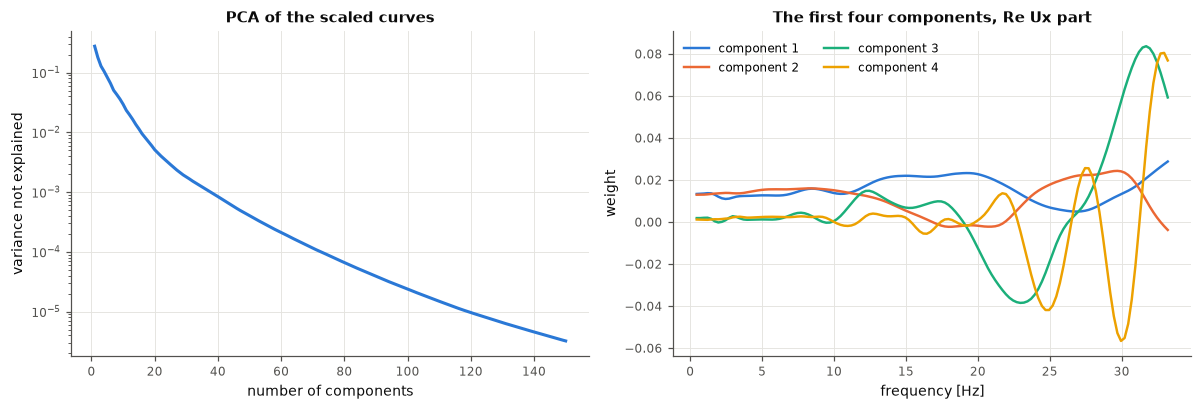

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.semilogy(np.arange(1, 151), 1 - cum[:150], color=style.SERIES[0])
ax.set(xlabel="number of components", ylabel="variance not explained", title="PCA of the scaled curves")
ax = axes[1]
cols = spec.columns("Ux", "re")
for c in range(4):
    ax.plot(f, pca_full.components_[c, cols], color=style.SERIES[c], lw=1.6, label=f"component {c + 1}")
ax.set(xlabel="frequency [Hz]", ylabel="weight", title="The first four components, Re Ux part")
ax.legend(ncol=2)
fig.tight_layout()

The curves need many components: 16 for 99 % of the variance, close to 40 for 99.9 %. A
response made of a few fixed shapes would need far fewer. The reason was flagged in notebook
01: the curves' features **move** with the soil (the dip follows f0, and the ripples above
~15 Hz shift with every layer thickness), and a moving feature is not a sum of a few fixed
shapes.

The reconstruction table sets the **floor**: a model that predicted 40 coefficients perfectly
would still be off by the 40-component reconstruction error. 40 components are kept below.

## 4 · Gaussian processes on the PCA coefficients

`PCAGP` (in `surrogate/models.py`) chains it all: standardise inputs → scale targets → PCA (40
components) → one Gaussian process per coefficient. Each GP has a Matérn 5/2 kernel (a common
default for physical responses: smooth, but less rigidly so than the squared-exponential) with
**one length scale per input**, plus a small white-noise term. Fitting each GP means maximising
its marginal likelihood over those hyperparameters; that is the slow part, run on all cores.

In [7]:
t0 = time.perf_counter()
gp = PCAGP(spec, n_components=40, n_jobs=-1).fit(X_train, Y_train)
gp_fit_s = time.perf_counter() - t0

t0 = time.perf_counter()
Y_gp, Y_gp_std = gp.predict(X_test, return_std=True)
gp_pred_ms = 1000 * (time.perf_counter() - t0) / len(X_test)
print(f"fit: {gp_fit_s:.0f} s for {gp.pca_.n_components_} GPs | prediction: {gp_pred_ms:.2f} ms per soil "
      f"(MISS3D: ~100 s per ref33x31 case, i.e. ~{100 / (gp_pred_ms / 1000):,.0f} times slower)")
e_gp, _ = evaluate("PCA(40) + GP", Y_gp)
show()

fit: 84 s for 40 GPs | prediction: 2.24 ms per soil (MISS3D: ~100 s per ref33x31 case, i.e. ~44,630 times slower)


,err_Ux,err_Uy,err_Uz,err_Rx,err_Ry,err_Rz,err_Ux-Ry,err_Uy-Rx,err_worst,err_mean
mean curve,65.59,65.73,30.67,39.50,38.53,39.74,78.37,74.14,78.37,33.59
kNN (k=13),37.78,38.02,22.58,12.52,12.29,17.70,55.79,51.56,55.79,18.01
PCA(40) + GP,26.85,26.72,13.79,2.85,2.98,9.22,47.39,44.71,47.39,11.45


Do all 40 coefficients help? The GPs are independent, so the same fitted model can be
evaluated with only its first n coefficients (the rest set to zero) at no extra cost.

In [8]:
A_pred = np.column_stack([g.predict(gp.x_scaler_.transform(X_test)) for g in gp.gps_])
rows = {}
for n in (5, 10, 20, 30, 40):
    A_n = A_pred.copy()
    A_n[:, n:] = 0
    Y_n = gp.y_scaler_.inverse_transform(gp.pca_.inverse_transform(A_n))
    s = summarize(target_errors(Y_test, Y_n, spec), terms)
    rows[n] = {"err_mean": s["err_mean"], "err_worst": s["err_worst"],
               "PCA floor err_mean": rec_table.loc[n, "err_mean"] if n in rec_table.index else np.nan}
pd.DataFrame(rows).T.rename_axis("coefficients used").round(2)

,err_mean,err_worst,PCA floor err_mean
coefficients used,,,
5,14.01,46.44,11.95
10,12.28,44.00,7.96
20,11.53,46.52,3.69
30,11.41,47.95,NaN
40,11.45,47.39,1.54


Beyond ~20 coefficients the full-band prediction stops improving although the floor keeps
falling (below 10 Hz the extra coefficients still help a little): the
higher coefficients describe the shifting ripples, which change too quickly with the inputs for
1,024 soils in eight dimensions to pin down. The GP then predicts roughly their average (zero),
which is the honest thing to do when it does not know.

## 5 · Where the error comes from

The deviation at each frequency, in % of the curve's max |K|, for the GP on the 32 test soils
(95th percentile over the soils).

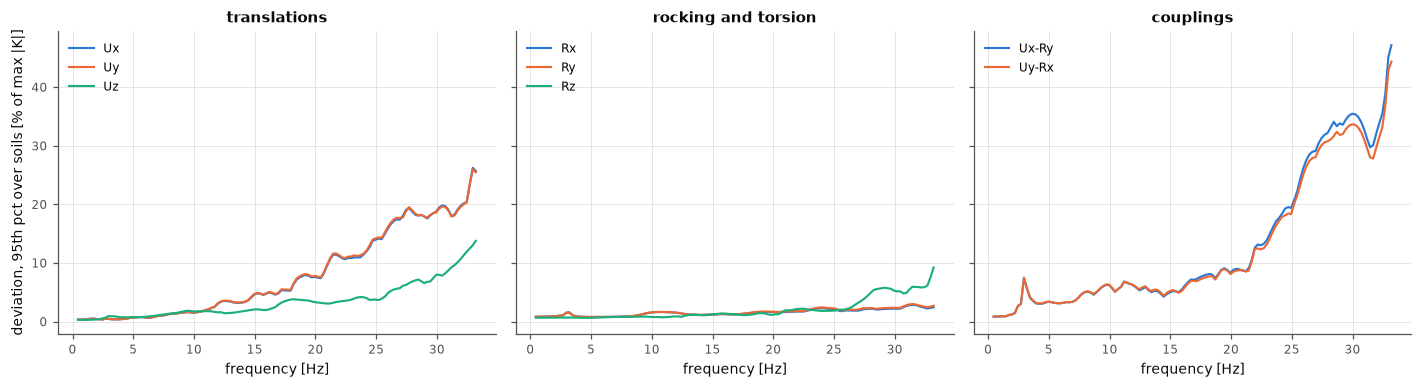

In [9]:
spec_err = error_spectrum(Y_test, Y_gp, spec)              # (soil, freq, term)
p95 = np.percentile(spec_err, 95, axis=0)
groups = [("translations", ["Ux", "Uy", "Uz"]), ("rocking and torsion", ["Rx", "Ry", "Rz"]),
          ("couplings", ["Ux-Ry", "Uy-Rx"])]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, (title, names) in zip(axes, groups):
    for c, name in enumerate(names):
        ax.plot(f, p95[:, terms.index(name)], color=style.SERIES[c], lw=1.4, label=name)
    ax.set(title=title, xlabel="frequency [Hz]")
    ax.legend(loc="upper left")
axes[0].set_ylabel("deviation, 95th pct over soils [% of max |K|]")
fig.tight_layout()

In [10]:
bands = [(0.45, 10), (10, 20), (20, 33.2)]
band_rows = {}
for lo, hi in bands:
    e = target_errors(Y_test, Y_gp, spec, freqs=f, band=(lo, hi))
    s = summarize(e, terms)
    band_rows[f"{lo:g}-{hi:g} Hz"] = {k.replace("err_", ""): v for k, v in s.items()}
band_table = pd.DataFrame(band_rows).T.round(2)
band_table

,Ux,Uy,Uz,Rx,Ry,Rz,Ux-Ry,Uy-Rx,worst,mean
0.45-10 Hz,1.75,1.78,1.89,1.78,1.73,0.87,7.79,7.78,7.79,1.38
10-20 Hz,8.65,8.85,4.18,1.77,1.80,1.72,9.69,9.51,9.69,2.87
20-33.2 Hz,26.85,26.72,13.79,2.85,2.98,9.22,47.39,44.71,47.39,11.45


The error is concentrated at high frequency. Below 10 Hz the six diagonal terms are within
about 2 % for 95 % of new soils; the couplings are harder (they step sharply at the soil
column's resonance). Above 20 Hz the translations and couplings carry fine ripples from wave
reflections between the layers, and that is where the full-band metric is lost.

That is worth knowing for the use: the band that matters most for soil-structure interaction is
the one around the structure's own modes, typically well below 15 Hz.

## 6 · Examples, with the GP's uncertainty

The median and the worst test soil (by mean error), for three terms. The shaded band is ±2σ
from the GPs, propagated through the PCA basis (it leaves out the PCA truncation error). If the
uncertainty were calibrated, about 95 % of the true values would fall inside it.

share of test values inside ±2σ (calibrated: 95 %):
  0.45-10 Hz: 99.7%   (Ux 100%, Uy 100%, Uz 100%, Rx 100%, Ry 100%, Rz 100%, Ux-Ry 99%, Uy-Rx 99%)
  10-20 Hz: 99.4%   (Ux 99%, Uy 99%, Uz 98%, Rx 100%, Ry 100%, Rz 100%, Ux-Ry 99%, Uy-Rx 99%)
  20-33.2 Hz: 95.8%   (Ux 94%, Uy 95%, Uz 97%, Rx 100%, Ry 99%, Rz 97%, Ux-Ry 93%, Uy-Rx 93%)


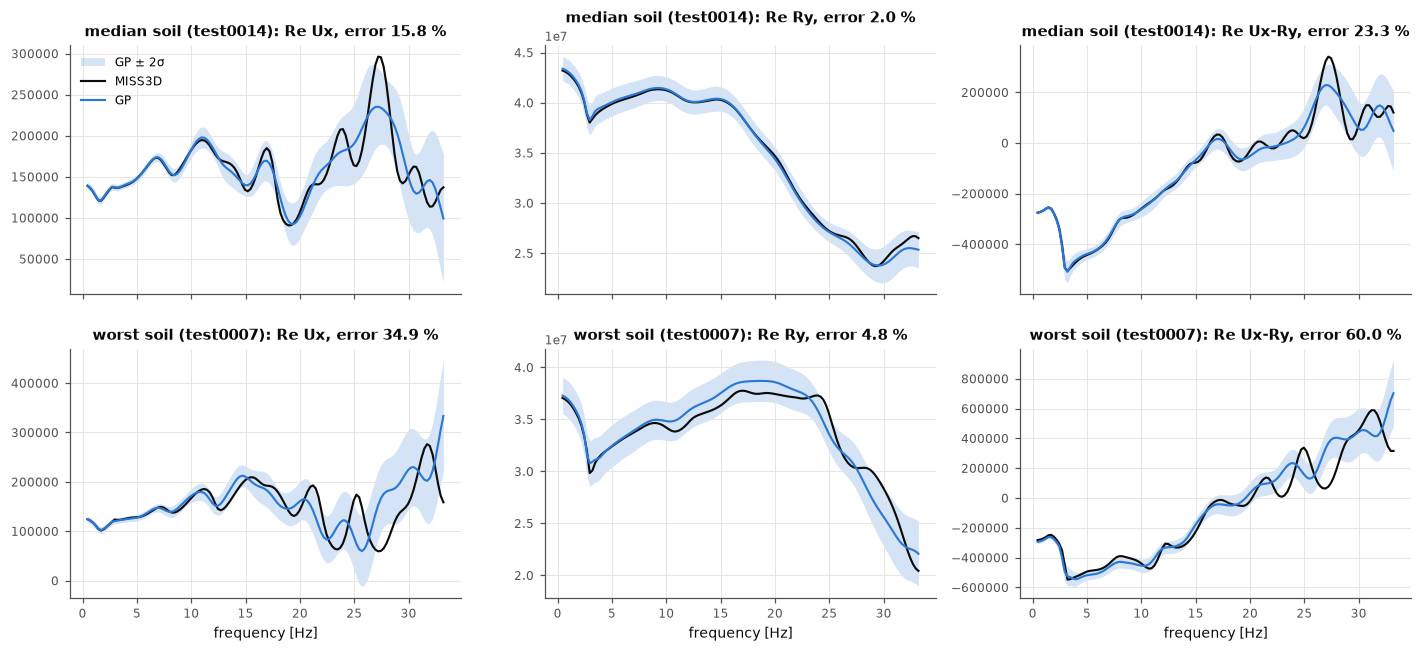

In [11]:
per_soil = e_gp.mean(axis=1)
picks = {"median soil": int(np.argsort(per_soil)[len(per_soil) // 2]), "worst soil": int(np.argmax(per_soil))}
K_true, K_pred = targets_to_K(Y_test, spec), targets_to_K(Y_gp, spec)
K_std = targets_to_K(Y_gp_std, spec).real                  # std of the Re columns
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharex=True)
for r, (label, i) in enumerate(picks.items()):
    for c, name in enumerate(["Ux", "Ry", "Ux-Ry"]):
        t = terms.index(name)
        ax = axes[r, c]
        ax.fill_between(f, K_pred[i, :, t].real - 2 * K_std[i, :, t], K_pred[i, :, t].real + 2 * K_std[i, :, t],
                        color=style.SERIES[0], alpha=0.2, lw=0, label="GP ± 2σ")
        ax.plot(f, K_true[i, :, t].real, color=style.INK, lw=1.4, label="MISS3D")
        ax.plot(f, K_pred[i, :, t].real, color=style.SERIES[0], lw=1.4, label="GP")
        ax.set_title(f"{label} ({test.case[i].split('_')[1]}): Re {name}, error {e_gp[i, t]:.1f} %")
axes[0, 0].legend(loc="upper left")
for ax in axes[1]:
    ax.set_xlabel("frequency [Hz]")
fig.tight_layout()

inside = (np.abs(Y_gp - Y_test) <= 2 * Y_gp_std).reshape(len(Y_test), len(terms), 2, len(f))
print("share of test values inside ±2σ (calibrated: 95 %):")
for lo, hi in bands:
    b = (f >= lo) & (f <= hi)
    per_term = ", ".join(f"{t} {v:.0%}" for t, v in zip(terms, inside[..., b].mean(axis=(0, 2, 3))))
    print(f"  {lo:g}-{hi:g} Hz: {inside[..., b].mean():.1%}   ({per_term})")

## 7 · Learning curves: would more data help?

Train on the first n soils (n = 32 … 1,024) and test on the same 32 hold-out soils. Because
the training soils come from a Halton sequence, every prefix is itself a space-filling design,
so each n is a proper experiment. The slope says what more data would buy; a flat curve says
the model or the representation is the limit.

In [12]:
sizes = [32, 64, 128, 256, 512, 1024]
curve = {"kNN": [], "PCA(40) + GP": []}
curve_low = {"kNN": [], "PCA(40) + GP": []}
for n in sizes:
    models = {"kNN": knn_model(spec, k=min(best_k, n)).fit(X_train[:n], Y_train[:n]),
              "PCA(40) + GP": gp if n == 1024 else PCAGP(spec, n_components=40, n_jobs=-1).fit(X_train[:n], Y_train[:n])}
    for name, m in models.items():
        Y_p = m.predict(X_test)
        curve[name].append(target_errors(Y_test, Y_p, spec).mean())
        curve_low[name].append(target_errors(Y_test, Y_p, spec, freqs=f, band=(0.45, 10)).mean())
    print(f"n = {n:4d}: kNN {curve['kNN'][-1]:5.2f} %   GP {curve['PCA(40) + GP'][-1]:5.2f} %   "
          f"(0.45-10 Hz: kNN {curve_low['kNN'][-1]:5.2f} %, GP {curve_low['PCA(40) + GP'][-1]:5.2f} %)")

n =   32: kNN 28.17 %   GP 21.68 %   (0.45-10 Hz: kNN 11.95 %, GP  4.21 %)
n =   64: kNN 25.81 %   GP 18.44 %   (0.45-10 Hz: kNN  9.93 %, GP  3.55 %)


n =  128: kNN 23.87 %   GP 16.29 %   (0.45-10 Hz: kNN  8.36 %, GP  2.93 %)


n =  256: kNN 22.18 %   GP 15.21 %   (0.45-10 Hz: kNN  7.21 %, GP  2.13 %)


n =  512: kNN 19.53 %   GP 13.01 %   (0.45-10 Hz: kNN  5.83 %, GP  1.60 %)
n = 1024: kNN 18.01 %   GP 11.45 %   (0.45-10 Hz: kNN  4.85 %, GP  1.38 %)


GP, full band: error ~ n^-0.18 from 128 soils up (doubling the data multiplies the error by 0.89)
GP, 0.45-10 Hz: error ~ n^-0.37 from 128 soils up (doubling the data multiplies the error by 0.78)


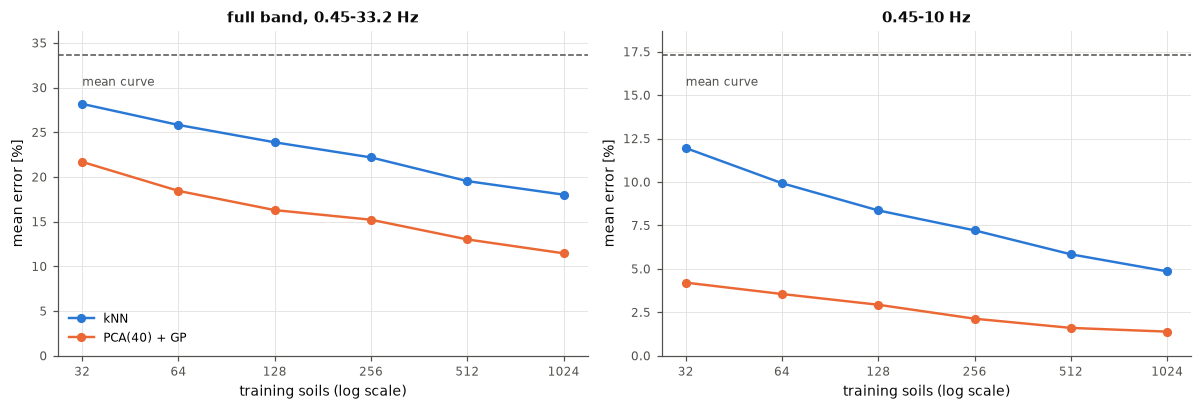

In [13]:
mean_full = target_errors(Y_test, mean_model.predict(X_test), spec).mean()
mean_low = target_errors(Y_test, mean_model.predict(X_test), spec, freqs=f, band=(0.45, 10)).mean()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
for ax, data, ref, title in [(axes[0], curve, mean_full, "full band, 0.45-33.2 Hz"),
                             (axes[1], curve_low, mean_low, "0.45-10 Hz")]:
    for c, (name, ys) in enumerate(data.items()):
        ax.plot(sizes, ys, "o-", color=style.SERIES[c], lw=1.6, ms=5, label=name)
    ax.axhline(ref, color=style.INK2, lw=1, ls="--")
    ax.text(sizes[0], ref * 0.93, "mean curve", color=style.INK2, fontsize=8, va="top")
    ax.set_xscale("log", base=2)
    ax.set(title=title, xlabel="training soils (log scale)", ylabel="mean error [%]", ylim=(0, ref * 1.08))
    ax.set_xticks(sizes, [str(s) for s in sizes])
    ax.minorticks_off()
axes[0].legend(loc="lower left")
fig.tight_layout()
for label, data in [("full band", curve), ("0.45-10 Hz", curve_low)]:
    slope = np.polyfit(np.log(sizes[2:]), np.log(data["PCA(40) + GP"][2:]), 1)[0]
    print(f"GP, {label}: error ~ n^{slope:.2f} from 128 soils up "
          f"(doubling the data multiplies the error by {2 ** slope:.2f})")

## 8 · What the GP learned about the inputs

Each GP fitted one length scale per input (in standardised units). A short length scale means
the coefficient changes quickly along that input; a long one means the input barely matters
for it. The map shows the relevance, 1 / length scale, for the first ten coefficients, divided by
each row's largest value so that every coefficient's pattern is visible.

,t_L1,t_L2,t_L3,t_L4,t_L5,t_L6,t_L7,log_g
PC 1,13.32,23.41,12.45,30.66,20.78,40.91,1000.00,6.48
PC 2,9.12,13.54,6.90,16.88,105.03,332.34,1000.00,5.63
PC 3,2.98,4.59,2.47,6.07,1.72,2.13,26.15,0.90


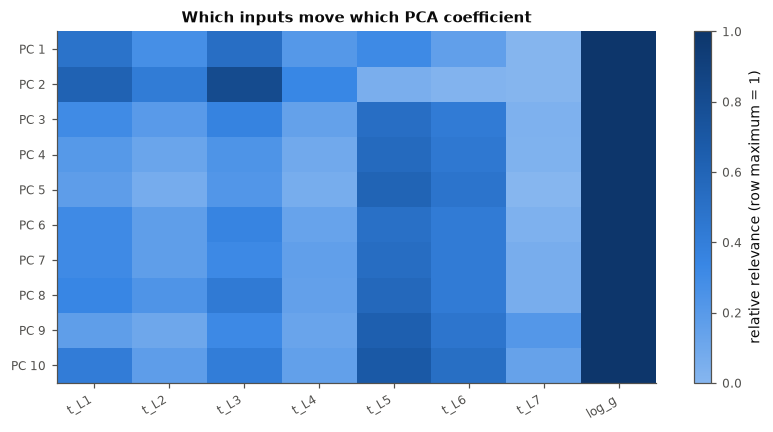

In [14]:
L = gp.length_scales()[:10]
rel = 1 / L
rel = rel / rel.max(axis=1, keepdims=True)                # each row: most relevant input = 1
fig, ax = plt.subplots(figsize=(7.5, 4))
im = ax.imshow(rel, cmap=style.SEQ, aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(len(x_names)), x_names, rotation=30, ha="right")
ax.set_yticks(range(10), [f"PC {i + 1}" for i in range(10)])
ax.grid(False)
fig.colorbar(im, ax=ax, label="relative relevance (row maximum = 1)")
ax.set_title("Which inputs move which PCA coefficient")
fig.tight_layout()
pd.DataFrame(L[:3], index=["PC 1", "PC 2", "PC 3"], columns=x_names).round(2)

g matters most to every coefficient (it scales all the stiffnesses). Beyond that, two groups
appear:

- **PC 1 and PC 2** (mostly the overall level and slope of the curves) depend on the shallow
  strata, L1 and L3. The deepest stratum, L7, barely matters, as you would expect for a
  33 × 31 m raft whose stress bulb fades with depth.
- **PC 3 and above** (the finer detail) depend most on L5 and L6: the two soft strata
  (Vs = 500 m/s) sandwiched between stiffer ones. Their contrast reflects waves, and those
  reflections are the ripples that the high band is made of.

So the GP has recovered, from data alone, which parts of the profile control which features of
the response.

## 9 · The experiment table

Each result is logged with its settings, timing and git commit. Re-running the notebook
replaces these rows instead of adding new ones.

In [15]:
common = dict(milestone="M2", footprints="ref33x31", validation="hold-out 32 random soils",
              n_train=len(X_train), n_test=len(X_test))
full = "0.45-33.2"
log_experiment("M2-mean", band_hz=full, representation="raw targets", model="mean curve (DummyRegressor)",
               **common, **results["mean curve"])
log_experiment("M2-knn", band_hz=full, representation="per-term scaled", model=f"kNN k={best_k}, distance-weighted",
               fit_s=knn_fit_s, **common, **results[f"kNN (k={best_k})"])
log_experiment("M2-pcagp40", band_hz=full, representation="per-term scaled, PCA 40",
               model="GP per coefficient, Matern 5/2 ARD + white noise", fit_s=gp_fit_s,
               predict_ms_per_case=gp_pred_ms, **common, **results["PCA(40) + GP"])
e_low, s_low = evaluate("PCA(40) + GP, 0.45-10 Hz", Y_gp, band=(0.45, 10))
log_experiment("M2-pcagp40-low", band_hz="0.45-10", representation="per-term scaled, PCA 40",
               model="GP per coefficient, Matern 5/2 ARD + white noise", fit_s=gp_fit_s,
               predict_ms_per_case=gp_pred_ms, notes="same model as M2-pcagp40, error measured below 10 Hz",
               **common, **s_low)
read_experiments()[["exp_id", "band_hz", "model", "err_worst", "err_mean", "fit_s", "git_commit"]]

,exp_id,band_hz,model,err_worst,err_mean,fit_s,git_commit
0,M3-ref-band15,0.45-14.95,"GP per coefficient, Matern 5/2 ARD",5.380,1.505,47.65000,7fc6ca1+dirty
1,M3-all-pcagp,0.45-14.95,"GP per coefficient, Matern 5/2 ARD",12.330,4.230,164.10000,7fc6ca1+dirty
2,M3-lofo-pcagp-all,0.45-14.95,"GP per coefficient, Matern 5/2 ARD",487.300,68.990,88.78000,7fc6ca1+dirty
3,M3-lofo-pcagp-interp,0.45-14.95,"GP per coefficient, Matern 5/2 ARD",280.700,50.620,88.78000,7fc6ca1+dirty
4,M3-all-static,0.45-14.95,GP per log-static and per shape coefficient,10.900,3.207,236.60000,7fc6ca1+dirty
5,M3-lofo-static-all,0.45-14.95,GP per log-static and per shape coefficient,82.770,16.920,145.40000,7fc6ca1+dirty
6,M3-lofo-static-interp,0.45-14.95,GP per log-static and per shape coefficient,11.740,5.206,145.40000,7fc6ca1+dirty
7,M3-fix-trend-4,0.45-14.95,"GP per target, Matern 5/2 ARD, linear trend",31.370,11.900,NaN,7fc6ca1+dirty
8,M3-fix-trend-interp,0.45-14.95,"GP per target, Matern 5/2 ARD, linear trend",19.050,5.155,NaN,7fc6ca1+dirty
9,M3-fix-trend-rot-4,0.45-14.95,"GP per target, Matern 5/2 ARD, linear trend, r...",21.990,9.775,NaN,7fc6ca1+dirty


## 10 · Findings

**Numbers (ref33x31, 1,024 training soils, 32 hold-out soils; errors as defined in section 1).**

| Model | err_mean | err_worst (95th pct, worst term) |
|---|---|---|
| Mean curve | 33.6 % | 78.4 % |
| kNN (k = 13, by cross-validation) | 18.0 % | 55.8 % |
| PCA(40) + GP, 0.45–33.2 Hz | 11.5 % | 47.4 % (Ux–Ry) |
| PCA(40) + GP, 0.45–10 Hz | 1.4 % | 7.8 % (couplings); diagonals ≤ 1.9 % |

Your run gives the same errors; timings depend on the machine (on a 2-core test machine the 40
GPs took about 4 minutes to fit and predicted in about 5 ms per soil).

**What they mean.**

1. **Below 10 Hz the surrogate already works:** the six diagonal terms within ~2 % for 95 % of
   new soils, in milliseconds instead of ~100 s per MISS3D run.
2. **The full-band error is set by the high-frequency ripples** of the translations and
   couplings above 20 Hz, which shift with every layer thickness. The couplings also step
   sharply near 3 Hz, at the soil column's resonance.
3. **PCA needs ~40 components** because the curves' features move, and the GP can only exploit
   about 20 of them: above 10 Hz the representation, not the regression, is the bottleneck.
4. **Learning curves:** the error falls as n^−0.37 below 10 Hz (doubling the data cuts it by a
   fifth) but only as n^−0.18 over the full band. More data helps most where the model already
   works; the high band needs a better representation.
5. **The uncertainty is roughly honest:** 99.4–99.7 % of test values fall inside ±2σ below
   20 Hz (cautious), 93–95 % for translations and couplings above 20 Hz (slightly
   over-confident). Calibration is a Milestone 5 item.
6. **The length scales make physical sense:** g matters most throughout; the overall level
   depends on the shallow strata (L1, L3) and hardly on the deepest (L7); the fine detail
   depends on the two soft strata (L5, L6) whose contrast creates the ripples.

**Next (Milestone 3):** all five footprints with L_x and L_y as inputs, leave-one-footprint-out
validation, and representations that line the moving features up (frequency normalised by f0,
curves normalised by their static value), which attack the bottleneck found here.